# General Setup Code

In [105]:
from pathlib import Path

import snntorch
import torch
import matplotlib.pyplot as plt
import snntorch.spikeplot as splt

from torchvision import datasets, transforms
from snntorch import utils, spikegen
from torch.utils.data import DataLoader
from IPython.display import HTML, display

In [106]:
batch_size = 128
num_classes = 10  # MNIST has 10 outputs

# Torch Variables
dtype = torch.float

# Directory paths
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file())

data_path = project_root / "data" / "raw"
data_path.mkdir(parents=True, exist_ok=True)
figure_path = project_root / "report" / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

# Tutorial 1 - Spike Encoding

In [107]:
subset = 10

transform = transforms.Compose([
    transforms.Resize((28,28)),
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0,), (1,))])

mnist_train = utils.data_subset(datasets.MNIST(data_path, train=True, download=True, transform=transform), subset)
train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)

print(f"Size of MNIST_train: {len(mnist_train)}")

Size of MNIST_train: 6000


In [108]:
# Temporal Dynamics
num_steps = 100

# create vector filled with 0.5
raw_vector = torch.ones(num_steps)*0.5

# pass each sample through a Bernoulli trial
rate_coded_vector = torch.bernoulli(raw_vector)

print(f"Converted vector: {rate_coded_vector}")
print(f"The output is spiking {rate_coded_vector.sum()*100/len(rate_coded_vector):.2f}% of the time.")

Converted vector: tensor([0., 1., 0., 0., 0., 1., 0., 0., 0., 1., 1., 1., 1., 1., 1., 0., 1., 0.,
        0., 0., 0., 1., 1., 0., 1., 1., 0., 1., 1., 1., 0., 1., 1., 0., 1., 1.,
        0., 1., 0., 0., 1., 1., 1., 0., 1., 1., 0., 1., 0., 0., 0., 0., 1., 0.,
        1., 1., 1., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
        1., 1., 1., 1., 0., 0., 1., 0., 0., 1., 0., 1., 0., 1., 0., 0., 0., 1.,
        1., 1., 0., 0., 0., 0., 1., 1., 1., 1.])
The output is spiking 50.00% of the time.


In [118]:
data = iter(train_loader)
data_it, targets_it = next(data)
plt.rcParams["animation.ffmpeg_path"] = str(
    Path.home() / "Tools" / "ffmpeg" / "bin" / "ffmpeg.exe")

In [119]:
spike_data = spikegen.rate(data_it, num_steps=num_steps)
spike_data_sample = spike_data[:, 0, 0]
print(spike_data.size())
print(spike_data_sample.size())

fig, ax = plt.subplots()
anim = splt.animator(spike_data_sample, fig, ax)
video = HTML(anim.to_html5_video())
plt.close(fig)
display(video)

animation_path = figure_path / "spike_mnist.mp4"
anim.save(animation_path, writer="ffmpeg")
print(f"Saved animation to {animation_path}")

torch.Size([100, 128, 1, 28, 28])
torch.Size([100, 28, 28])


Saved animation to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist.mp4


In [120]:
spike_data = spikegen.rate(data_it, num_steps=num_steps, gain=0.25)
spike_data_sample2 = spike_data[:, 0, 0]

fig, ax = plt.subplots()
anim = splt.animator(spike_data_sample2, fig, ax)
video = HTML(anim.to_html5_video())
plt.close(fig)
display(video)

animation_path = figure_path / "spike_mnist.mp4"
anim.save(animation_path, writer="ffmpeg")
print(f"Saved animation to {animation_path}")

Saved animation to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist.mp4


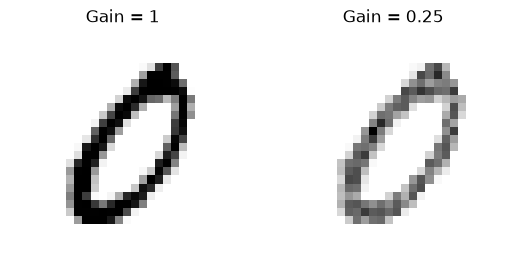

In [121]:
plt.figure(facecolor="w")
plt.subplot(1,2,1)
plt.imshow(spike_data_sample.mean(axis=0).reshape((28,-1)).cpu(), cmap='binary')
plt.axis('off')
plt.title('Gain = 1')

plt.subplot(1,2,2)
plt.imshow(spike_data_sample2.mean(axis=0).reshape((28,-1)).cpu(), cmap='binary')
plt.axis('off')
plt.title('Gain = 0.25')

plt.show()

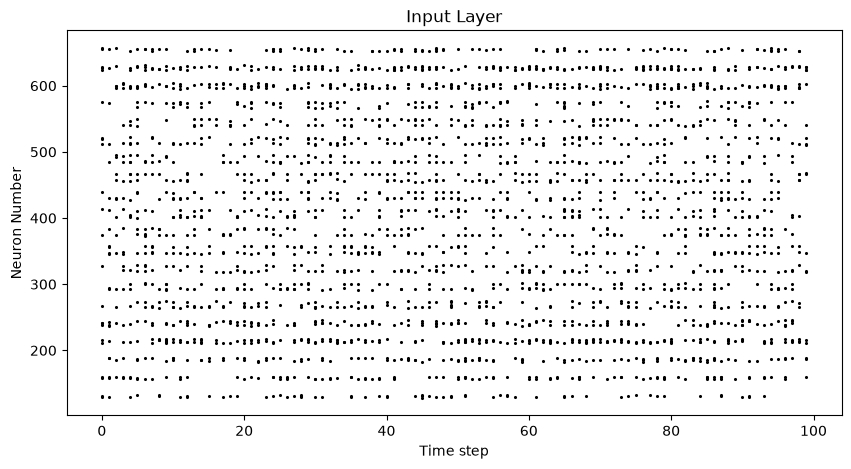

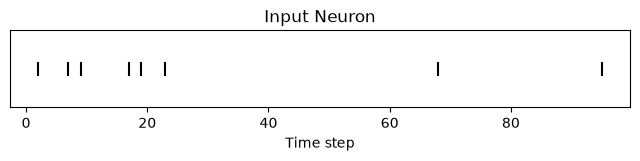

In [125]:
spike_data_sample2 = spike_data_sample2.reshape((num_steps, -1))

# raster plot
fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data_sample2, ax, s=1.5, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

idx = 210  # index into 210th neuron

fig = plt.figure(facecolor="w", figsize=(8, 1))
ax = fig.add_subplot(111)

splt.raster(spike_data_sample.reshape(num_steps, -1)[:, idx].unsqueeze(1), ax, s=100, c="black", marker="|")

plt.title("Input Neuron")
plt.xlabel("Time step")
plt.yticks([])
plt.show()

In [126]:
def convert_to_time(data, tau=5, threshold=0.01):
  spike_time = tau * torch.log(data / (data - threshold))
  return spike_time

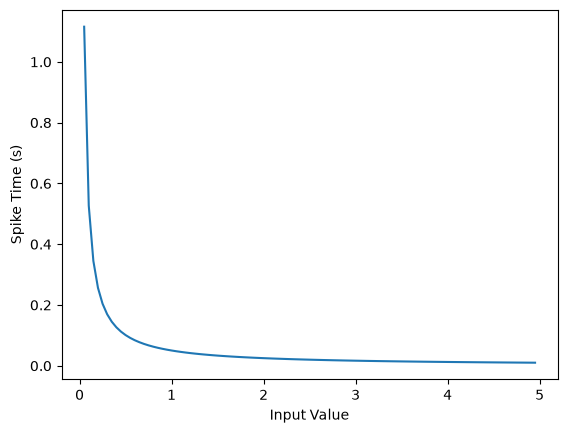

In [127]:
raw_input = torch.arange(0, 5, 0.05) # tensor from 0 to 5
spike_times = convert_to_time(raw_input)

plt.plot(raw_input, spike_times)
plt.xlabel('Input Value')
plt.ylabel('Spike Time (s)')
plt.show()

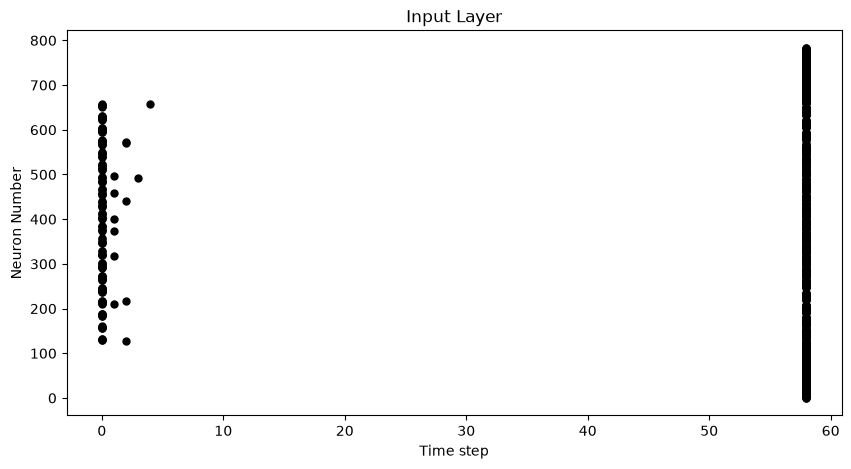

Saved image to c:\Users\willm\Projects\Programming\School Assignments\RUG-Work\Neural Networks\SNN_Project-Neural_Networks-RUG-\report\figures\spike_mnist_latency_raster.mp4


In [130]:
spike_data = spikegen.latency(data_it, num_steps=num_steps, tau=5, threshold=0.01)

fig = plt.figure(facecolor="w", figsize=(10, 5))
ax = fig.add_subplot(111)
splt.raster(spike_data[:, 0].view(num_steps, -1), ax, s=25, c="black")

plt.title("Input Layer")
plt.xlabel("Time step")
plt.ylabel("Neuron Number")
plt.show()

image_path = figure_path / "spike_mnist_latency_raster.mp4"
fig.savefig(image_path, format='png', dpi=300)
print(f"Saved image to {image_path}")